# Permanente evaluatie - vaardigheidstoets 2
16 november - 2ITAI - AP Hogeschool

## Opgave

Laad de volgende dataset in: de wine dataset via `from sklearn.datasets import load_wine` - deze dataset bevat informatie over wijnen, en 3 labels (class 0, class 1, class 2, hier is verder niets over gekend). Die labels hebben ze helemaal op het eind kort nodig.

Pas op deze dataset een datareductietechniek toe, en cluster vervolgens de gereduceerde dataset zo goed mogelijk. Zorg voor preprocessing waar nodig, en zoek naar een optimaal model. **Indien je bepaalde keuzes maakt, schrijf kort in de notebook waarom**. Vergelijk op het einde of de labels van je clusteringalgoritme overeenkomen met de originele labels `wine.target`, met behulp van een confusion matrix waarbij je de labels meegeeft en de clusters (clusters zijn het resultaat van `fit_predict()`). Trek hier conclusies uit en noteer deze in de notebook.

### Inleveren:
- Hernoem je bestand naar **PE2-VoornaamNaam.ipynb** waarbij je je *eigen naam* invult.
- Laadt dit bestand op naar de uploadzone op toets.ap.be voor het einde van deze test.

Jullie krijgen **60 minuten** de tijd.

### Indicatieve puntenverdeling /20
- goede algoritmes: 2 keer 4 ptn
- goede beschrijving over keuze van deze algoritmes: 4 ptn
- overige noodzakelijke stappen: 8 ptn
- Hierna wordt er gekeken naar code stijl

## Meer info over de dataset
Te verkrijgen via 
```python
wine = load_wine()
print(wine.DESCR)
```

# Oplossing

In [18]:
# Code
from sklearn import datasets

#data inladen
wine = datasets.load_wine()

# Data verkennen
wine 
X = wine.data
y = wine.target


In [13]:
X.shape #om te zien hvl rij en cols dataset heeft.

(178, 13)

In [25]:
y # ik heb 3 soorten labels: 0, 1, 2 dus in total 3 soorten categorien

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2])

In [27]:
from sklearn.preprocessing import StandardScaler

# Schaal de data zodat alle features gelijk gewicht krijgen
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [48]:
# Nu pas ik dimensie reductie toe op de kolommen
from sklearn.decomposition import PCA

pca = PCA(n_components=0.95)
X_pca_wine = pca.fit_transform(X_scaled)

n_components_wine = X_pca_wine.shape[1]
reduction_pct_wine = (1 - n_components_wine / X.shape[1]) * 100

print(f"Aantal features na reductie: {n_components_wine}")
print(f"Gereduceerde data: {reduction_pct_wine:.2f}%")


Aantal features na reductie: 10
Gereduceerde data: 23.08%


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


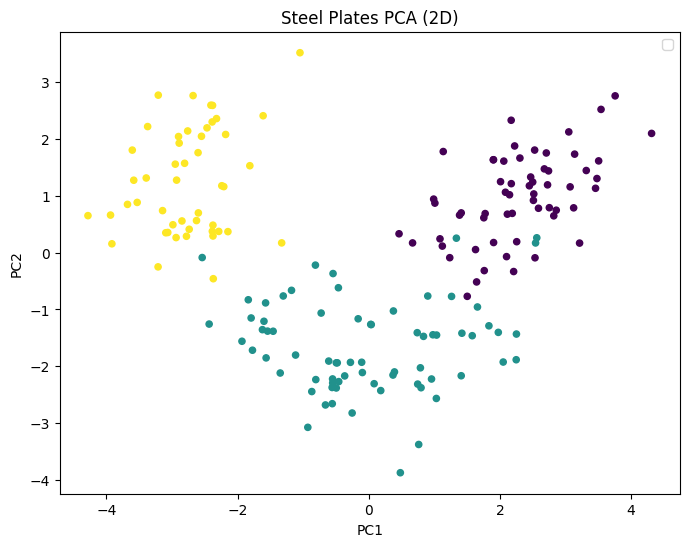

In [42]:
import matplotlib.pyplot as plt

pca_2 = PCA(n_components=2) #data geprojecteerd op 2 dimensies
X_2 = pca_2.fit_transform(X_scaled) # dataset reduced to 2D

plt.figure(figsize=(8, 6))

plt.scatter(X_2[:, 0], X_2[:, 1], s=20, c=y)
plt.title("Steel Plates PCA (2D)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()

#hier heb ik de dataset gereduceerd tot 2 om te zien hoe de dataset eruit ziet.
#In de grafiek zie ik dat de dataset verdeelt is in 3 clusters exact zoals ik het gezien had bij y
#Door deze grafiek is het duidelijk dat de beste cluster algoritme kmeans is omdat de dataset verdeeld it in 3 bolvormige groepen

In [56]:
#Aan de hand van de bovenstaande grafiek heb de KMeans algoritome gekozen
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


kmeans = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_pca_wine)
sil = silhouette_score(X_pca_wine, kmeans.labels_)

print(sil) 

# Uit de bovenstaande analyse
# waardes van y te bekijken en 2de dimensie van de data te bekijken was het duidelijk dat de beste k = 3 is.
#

0.2986748294369289


3
0.2986748294369289


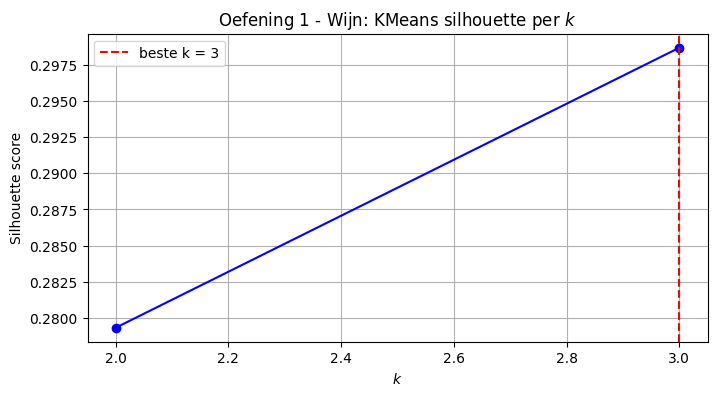

In [55]:
#Toch voor de zekerheid heb ik gelooped over het aantal mogelijke clusters en ik heb steeds dezelfde antwoord gekregen.
k_range_wine = list(range(2, 4))
sil_scores_wine = []
best_sil = -1.0
best_k_wine = 2
for k in k_range_wine:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_pca_wine)
    sil = silhouette_score(X_pca_wine, kmeans.labels_)
    sil_scores_wine.append(sil)
    if sil > best_sil:
        best_sil = sil
        best_k_wine = k
silhouette_wine = best_sil

print(f"{best_k_wine}")
print(f"{silhouette_wine}")

# Silhouette per k
plt.figure(figsize=(8, 4))
plt.plot(k_range_wine, sil_scores_wine, 'bo-')
plt.axvline(best_k_wine, color='red', linestyle='--', label=f'beste k = {best_k_wine}')

plt.xlabel('$k$')
plt.ylabel('Silhouette score')

plt.title('Oefening 1 - Wijn: KMeans silhouette per $k$')
plt.grid()
plt.legend()
plt.show()

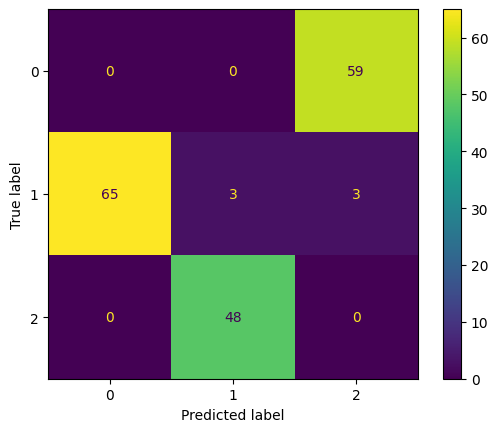

In [61]:
# Nu gat ik de resulaten in ConfusionMatrix gieten

from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

#ik zit hier vast dus ik ga dit verder doen in de tweede deel met AI:
cm = confusion_matrix(y, kmeans.labels_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

disp.plot()

In [63]:
# Dit deze confusion_matrix bewijst data goed verdeelt is in 3 clusters. 
# Hierbij heeft de tweede cluster de meeste data